TASK 1: DATA ACQUISITION AND EXPLORATION
Dataset shape: 569 rows, 31 columns
Target encoding: 0 = Malignant, 1 = Benign

Summary Statistics (first 10 features):


,count,mean,median,std,min,25%,50%,75%,iqr,max
mean radius,569.0,14.1273,13.3700,3.5240,6.9810,11.7000,13.3700,15.7800,4.0800,28.1100
mean texture,569.0,19.2896,18.8400,4.3010,9.7100,16.1700,18.8400,21.8000,5.6300,39.2800
mean perimeter,569.0,91.9690,86.2400,24.2990,43.7900,75.1700,86.2400,104.1000,28.9300,188.5000
mean area,569.0,654.8891,551.1000,351.9141,143.5000,420.3000,551.1000,782.7000,362.4000,2501.0000
mean smoothness,569.0,0.0964,0.0959,0.0141,0.0526,0.0864,0.0959,0.1053,0.0189,0.1634
mean compactness,569.0,0.1043,0.0926,0.0528,0.0194,0.0649,0.0926,0.1304,0.0655,0.3454
mean concavity,569.0,0.0888,0.0615,0.0797,0.0000,0.0296,0.0615,0.1307,0.1011,0.4268
mean concave points,569.0,0.0489,0.0335,0.0388,0.0000,0.0203,0.0335,0.0740,0.0537,0.2012
mean symmetry,569.0,0.1812,0.1792,0.0274,0.1060,0.1619,0.1792,0.1957,0.0338,0.3040
mean fractal dimension,569.0,0.0628,0.0615,0.0071,0.0500,0.0577,0.0615,0.0661,0.0084,0.0974



Total missing values: 0
Duplicate rows: 0

Top 10 features with 1.5*IQR outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64

Applied 1st/99th percentile winsorization to handle extreme outliers.


/tmp/ipykernel_4319/3996099793.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_labels, y=class_counts.values, palette=["#d9534f", "#5cb85c"], ax=ax)


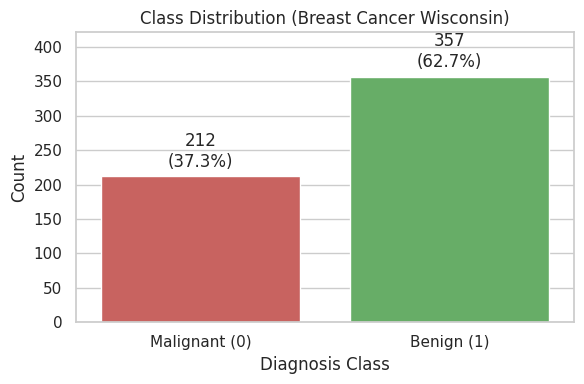

/tmp/ipykernel_4319/3996099793.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4319/3996099793.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4319/3996099793.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4319/3996099793.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4319/3996099793.py:123: FutureWarning

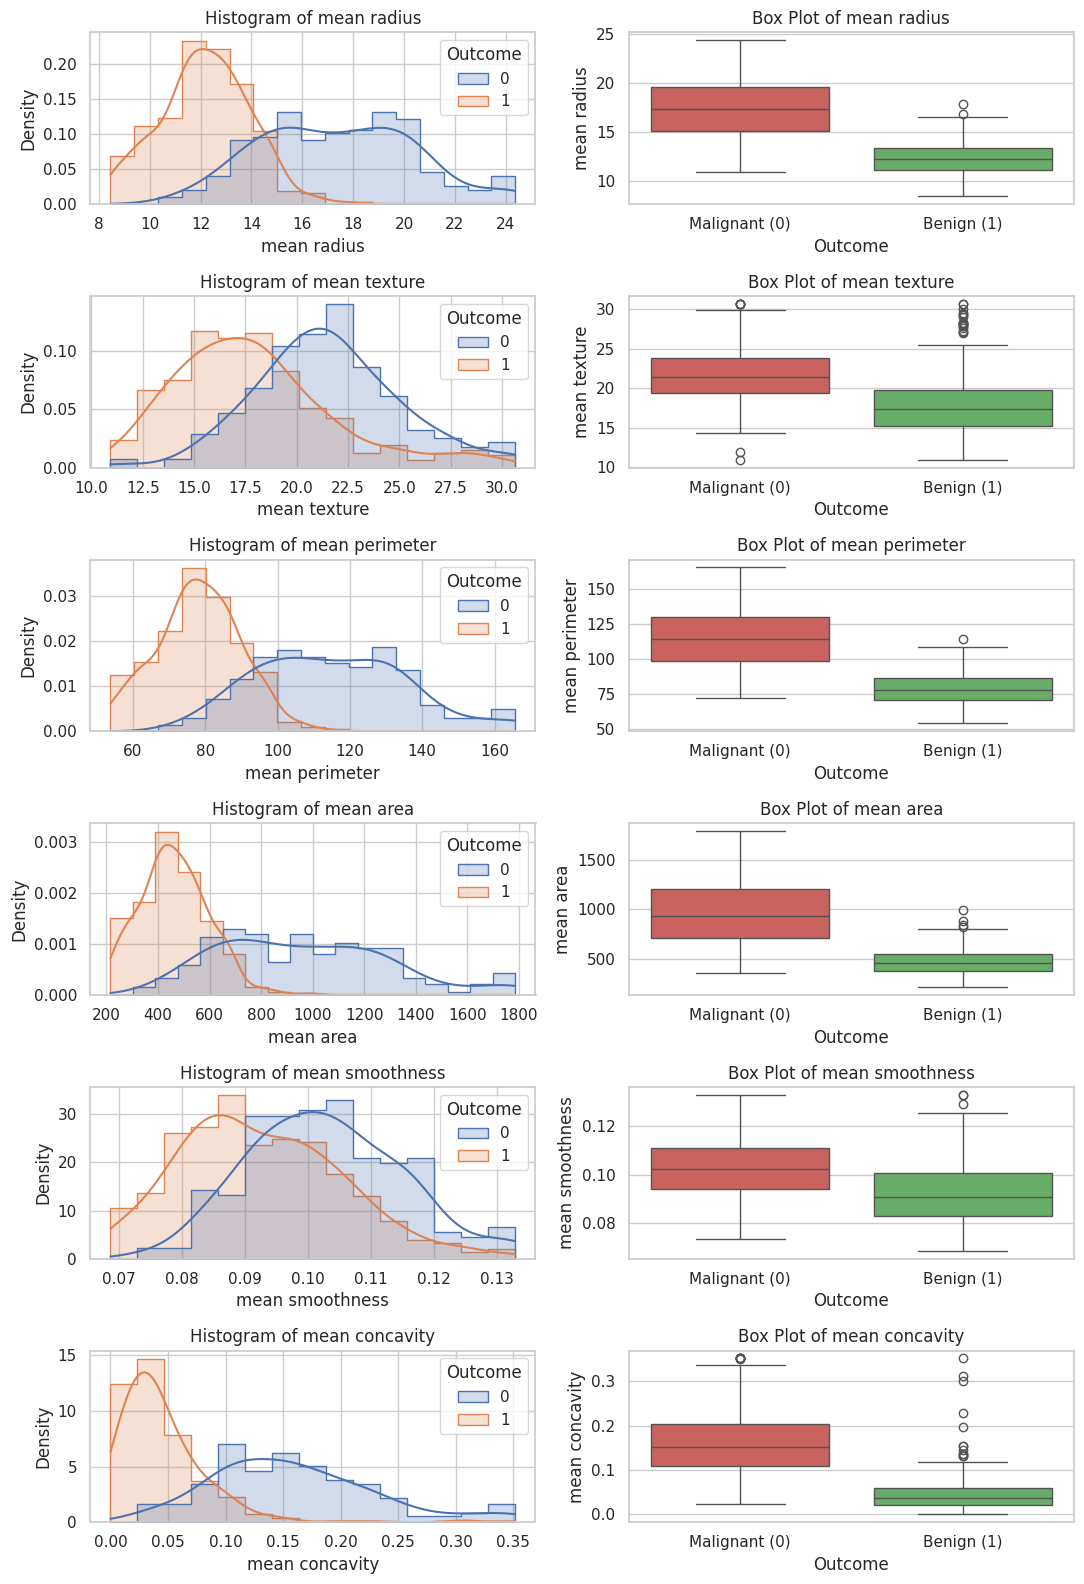

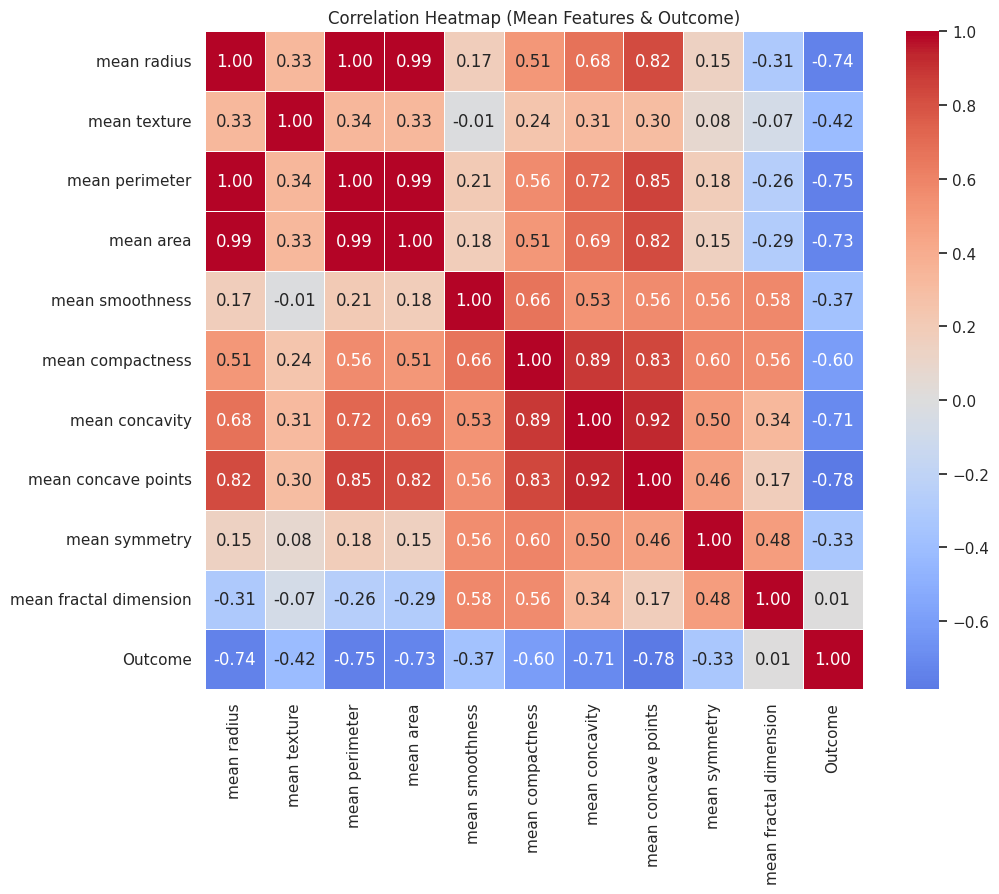


5. Class Imbalance Discussion:
   - Benign accounts for 62.7% and Malignant for 37.3% (~1.7:1 ratio).
   - Mild imbalance can still bias a model toward the majority class, and in
     cancer screening a False Negative (missing a malignant case) carries high
     clinical risk. Stratified splitting and recall/ROC-AUC tracking help address this.

TASK 2: DATA PREPROCESSING
Train shape: (455, 30) | Test shape: (114, 30)
Train benign rate: 0.6264 | Test benign rate: 0.6316

TASK 3: MODEL TRAINING AND BASIC EVALUATION
Accuracy : 0.9825
ROC-AUC  : 0.9950

               precision    recall  f1-score   support

Malignant (0)     0.9762    0.9762    0.9762        42
   Benign (1)     0.9861    0.9861    0.9861        72

     accuracy                         0.9825       114
    macro avg     0.9812    0.9812    0.9812       114
 weighted avg     0.9825    0.9825    0.9825       114



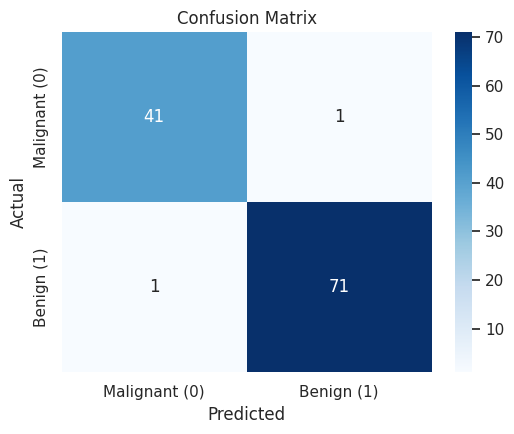

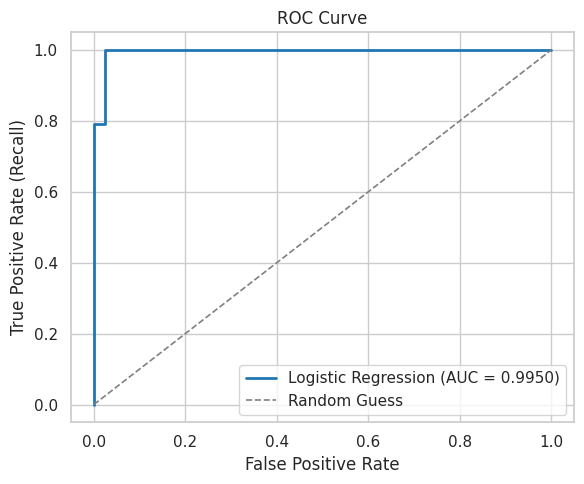

Interpretation:
   - Strong accuracy and ROC-AUC show clear separation between malignant and
     benign tumors after standardization.
   - In medical diagnosis, high recall on Malignant (0) is vital to avoid
     missed cancer diagnoses; lowering the probability threshold can prioritize
     sensitivity if needed.


In [1]:


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
)

os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")

# =============================================================================
# TASK 1: Data Acquisition and Exploration
# =============================================================================
print("=" * 70)
print("TASK 1: DATA ACQUISITION AND EXPLORATION")
print("=" * 70)

# 1. Load the dataset (0 = Malignant, 1 = Benign in sklearn)
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df.rename(columns={"target": "Outcome"}, inplace=True)

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("Target encoding: 0 = Malignant, 1 = Benign\n")

# 2. Summary statistics (mean, median, std, IQR, min, max, etc.)
feature_cols = [col for col in df.columns if col != "Outcome"]
summary_stats = df[feature_cols].describe().T
summary_stats["median"] = df[feature_cols].median()
summary_stats["iqr"] = summary_stats["75%"] - summary_stats["25%"]
summary_stats = summary_stats[
    ["count", "mean", "median", "std", "min", "25%", "50%", "75%", "iqr", "max"]
]
print("Summary Statistics (first 10 features):")
display(summary_stats.head(10).round(4))
summary_stats.to_csv("outputs/summary_statistics.csv")

# 3. Check missing values, duplicates, and outliers
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count}")
if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)

Q1 = df[feature_cols].quantile(0.25)
Q3 = df[feature_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_counts = (
    ((df[feature_cols] < (Q1 - 1.5 * IQR)) | (df[feature_cols] > (Q3 + 1.5 * IQR)))
    .sum()
    .sort_values(ascending=False)
)
print("\nTop 10 features with 1.5*IQR outliers:")
print(outlier_counts.head(10))

# Winsorize at 1st and 99th percentiles to reduce extreme skew without losing rows
df_clean = df.copy()
lower = df_clean[feature_cols].quantile(0.01)
upper = df_clean[feature_cols].quantile(0.99)
df_clean[feature_cols] = df_clean[feature_cols].clip(lower=lower, upper=upper, axis=1)
print("\nApplied 1st/99th percentile winsorization to handle extreme outliers.")

# 4a. Class distribution
class_counts = df_clean["Outcome"].value_counts().sort_index()
class_pct = (class_counts / len(df_clean)) * 100
class_labels = ["Malignant (0)", "Benign (1)"]

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=class_labels, y=class_counts.values, palette=["#d9534f", "#5cb85c"], ax=ax)
for i, count in enumerate(class_counts.values):
    ax.text(i, count + 8, f"{count}\n({class_pct.iloc[i]:.1f}%)", ha="center", va="bottom")
ax.set_title("Class Distribution (Breast Cancer Wisconsin)")
ax.set_xlabel("Diagnosis Class")
ax.set_ylabel("Count")
ax.set_ylim(0, max(class_counts.values) * 1.18)
plt.tight_layout()
plt.savefig("outputs/class_distribution.png", dpi=300)
plt.show()

# 4b. Histograms & Box plots for key features
key_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity",
]
fig, axes = plt.subplots(len(key_features), 2, figsize=(11, 16))
for i, feat in enumerate(key_features):
    sns.histplot(
        data=df_clean,
        x=feat,
        hue="Outcome",
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=axes[i, 0],
    )
    axes[i, 0].set_title(f"Histogram of {feat}")

    sns.boxplot(
        data=df_clean,
        x="Outcome",
        y=feat,
        palette=["#d9534f", "#5cb85c"],
        ax=axes[i, 1],
    )
    axes[i, 1].set_xticks([0, 1])
    axes[i, 1].set_xticklabels(["Malignant (0)", "Benign (1)"])
    axes[i, 1].set_title(f"Box Plot of {feat}")

plt.tight_layout()
plt.savefig("outputs/feature_distributions.png", dpi=300)
plt.show()

# 4c. Correlation heatmap
corr_cols = [c for c in df_clean.columns if c.startswith("mean ")] + ["Outcome"]
plt.figure(figsize=(11, 9))
sns.heatmap(
    df_clean[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("Correlation Heatmap (Mean Features & Outcome)")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png", dpi=300)
plt.show()

# 5. Class imbalance notes
print("\n5. Class Imbalance Discussion:")
print(
    f"   - Benign accounts for {class_pct.iloc[1]:.1f}% and Malignant for {class_pct.iloc[0]:.1f}% (~1.7:1 ratio).\n"
    "   - Mild imbalance can still bias a model toward the majority class, and in\n"
    "     cancer screening a False Negative (missing a malignant case) carries high\n"
    "     clinical risk. Stratified splitting and recall/ROC-AUC tracking help address this."
)

# =============================================================================
# TASK 2: Data Preprocessing
# =============================================================================
print("\n" + "=" * 70)
print("TASK 2: DATA PREPROCESSING")
print("=" * 70)

X = df_clean[feature_cols].copy()
y = df_clean["Outcome"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train shape: {X_train_scaled.shape} | Test shape: {X_test_scaled.shape}")
print(f"Train benign rate: {y_train.mean():.4f} | Test benign rate: {y_test.mean():.4f}")

# =============================================================================
# TASK 3: Model Training and Basic Evaluation
# =============================================================================
print("\n" + "=" * 70)
print("TASK 3: MODEL TRAINING AND BASIC EVALUATION")
print("=" * 70)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average=None)
rec = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {acc:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}\n")
print(
    classification_report(
        y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"], digits=4
    )
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant (0)", "Benign (1)"],
    yticklabels=["Malignant (0)", "Benign (1)"],
    ax=ax,
)
ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=300)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color="#1f77b4", lw=2, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1.2, linestyle="--", label="Random Guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC Curve")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("outputs/roc_curve.png", dpi=300)
plt.show()

print("Interpretation:")
print(
    "   - Strong accuracy and ROC-AUC show clear separation between malignant and\n"
    "     benign tumors after standardization.\n"
    "   - In medical diagnosis, high recall on Malignant (0) is vital to avoid\n"
    "     missed cancer diagnoses; lowering the probability threshold can prioritize\n"
    "     sensitivity if needed."
)